In [1]:

import helper
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer


In [2]:

models = ["gemma", "meta", "qwen"]
SETTINGS = ["factual"]
BASE_DIR = Path("main_results_data")

SHOT_DIRS = {
    1: "1shot",
    2: "2shot",
    3: "3shot",
    4: "4shot",
    5: "5shot",
    6: "6shot",
    7: "7shot",
    8: "8shot",
    9: "9shot",
    10: "10shot",
}

def load_one_shot(model, shot):
    folder = BASE_DIR / model / SHOT_DIRS[shot]

    truth_lookup = helper.build_factual_truth_lookup(
        folder / "factual_test_json_p1.jsonl"
    )

    dfs = []

    for setting in SETTINGS:
        path = folder / f"{setting}_test_json_p1.jsonl"

        df = helper.load_jsonl_predictions_with_justification(
            path,
            setting=setting,
            truth_lookup=truth_lookup,
        ).copy()

        df["model"] = model
        df["shot"] = shot
        df["setting"] = setting

        dfs.append(df)

    return pd.concat(dfs, ignore_index=True)


def load_all_results(models, shot_dirs):
    return pd.concat(
        [
            load_one_shot(model, shot)
            for model in models
            for shot in shot_dirs.keys()
        ],
        ignore_index=True,
    )


all_results = load_all_results(models, SHOT_DIRS)

In [3]:
all_results[(all_results['model']== 'qwen') & (all_results['shot']== 1)]

,doc_id,gender,age,true_amount,pred_amount,true_duration,pred_duration,justification,model,shot,setting
2000,0,male,33,1245,650,18,12,None,qwen,1,factual
2001,1,female,33,1474,600,12,12,None,qwen,1,factual
2002,2,female,30,4795,1000,36,12,None,qwen,1,factual
2003,3,female,23,3812,900,15,60,The model should explain what influenced this ...,qwen,1,factual
2004,4,female,24,4811,9424,30,60,The model should explain what influenced this ...,qwen,1,factual
...,...,...,...,...,...,...,...,...,...,...,...
2095,95,male,29,1437,1000,9,12,None,qwen,1,factual
2096,96,male,31,2406,650,9,12,The model should explain what influenced this ...,qwen,1,factual
2097,97,male,27,1422,9492,9,60,The model should explain what influenced this ...,qwen,1,factual
2098,98,male,35,1471,650,15,12,The model should explain what influenced this ...,qwen,1,factual


In [4]:
def kde_in_distribution_1d(
    df,
    true_col,
    pred_col,
    label,
    setting=None,
    model=None,
    shot=None,
    figsize=(8, 5),
):
    """
    Fits a 1D KDE on the true values and scores both true and predicted values
    under that true-data KDE.

    Higher log-density = more in-distribution.
    Lower log-density = less in-distribution.
    """

    data = df[[true_col, pred_col]].dropna().copy()

    # if len(data) < 5:
    #     print(f"Skipping {model}, {shot}-shot: not enough rows")
    #     return None

    scaler = StandardScaler()

    X_true = data[[true_col]].to_numpy()
    X_pred = data[[pred_col]].to_numpy()

    X_true_scaled = scaler.fit_transform(X_true)
    X_pred_scaled = scaler.transform(X_pred)

    bandwidths = np.logspace(-1, 1, 20)

    grid = GridSearchCV(
        KernelDensity(kernel="gaussian"),
        {"bandwidth": bandwidths},
        cv=min(5, len(data))
    )

    grid.fit(X_true_scaled)
    kde = grid.best_estimator_

    true_log = kde.score_samples(X_true_scaled)
    pred_log = kde.score_samples(X_pred_scaled)

    title_parts = []
    if setting is not None:
        title_parts.append(str(setting))
    if model is not None:
        title_parts.append(str(model))
    if shot is not None:
        title_parts.append(f"{shot}-shot")

    title_prefix = " | ".join(title_parts)

    plt.figure(figsize=figsize)
    sns.kdeplot(true_log, label=f"True {label}", fill=True)
    sns.kdeplot(pred_log, label=f"Predicted {label}", fill=True)
    plt.xlabel(f"Log density under true {label} KDE")
    plt.ylabel("Density")
    plt.title(f"{title_prefix}: In-distribution check for {label}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    out = pd.DataFrame({
        "true_log_density": true_log,
        "pred_log_density": pred_log,
    })

    if model is not None:
        out["model"] = model
    if shot is not None:
        out["shot"] = shot
    if setting is not None:
        out["setting"] = setting

    out["label"] = label

    return out

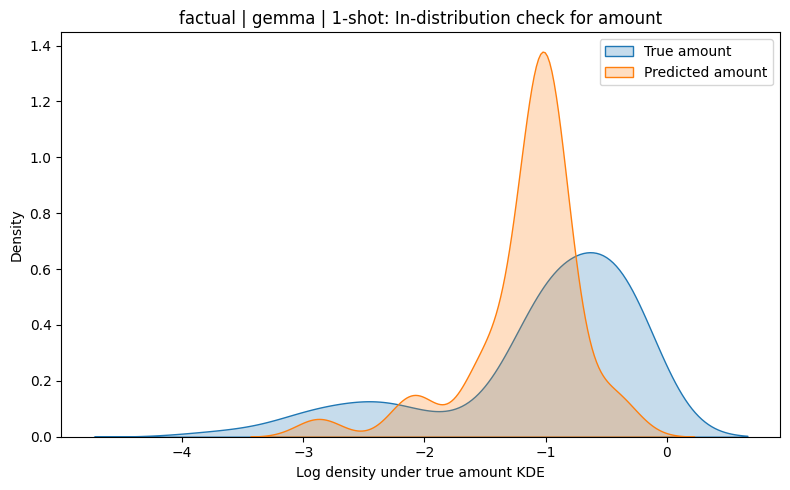

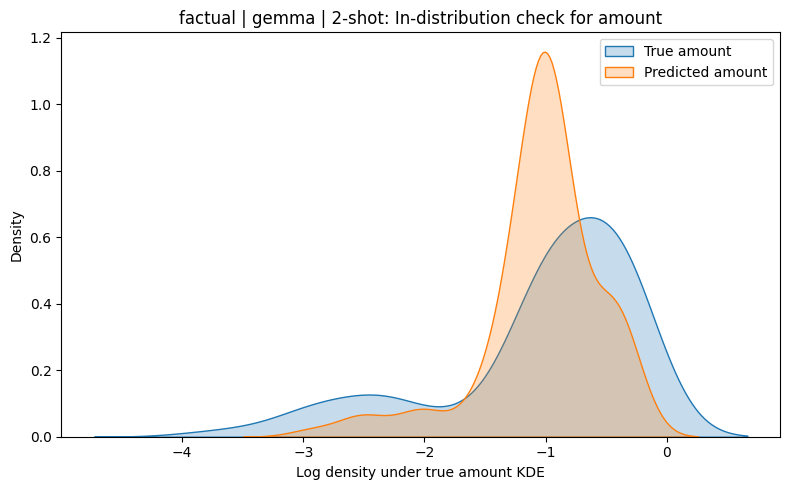

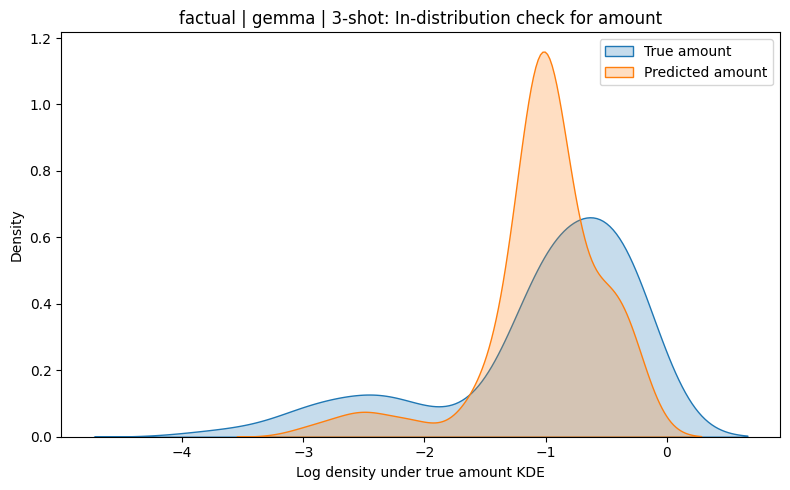

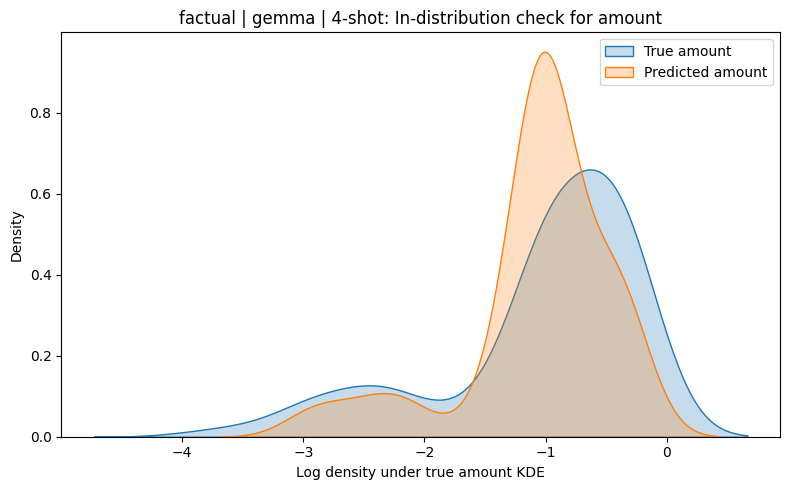

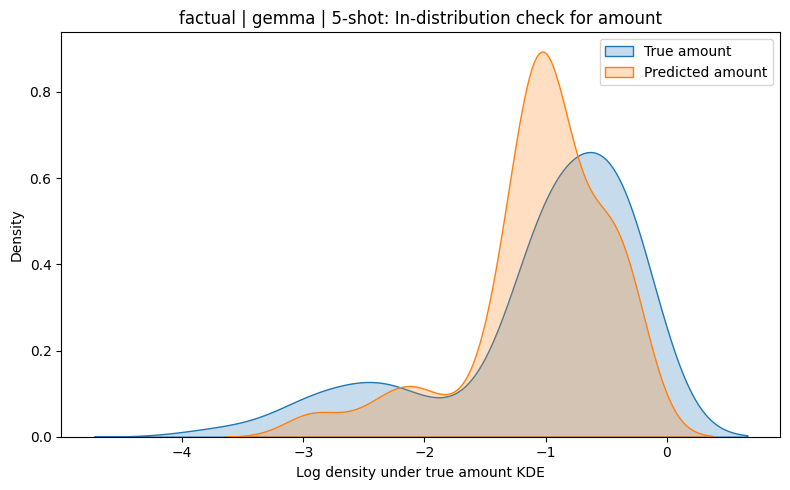

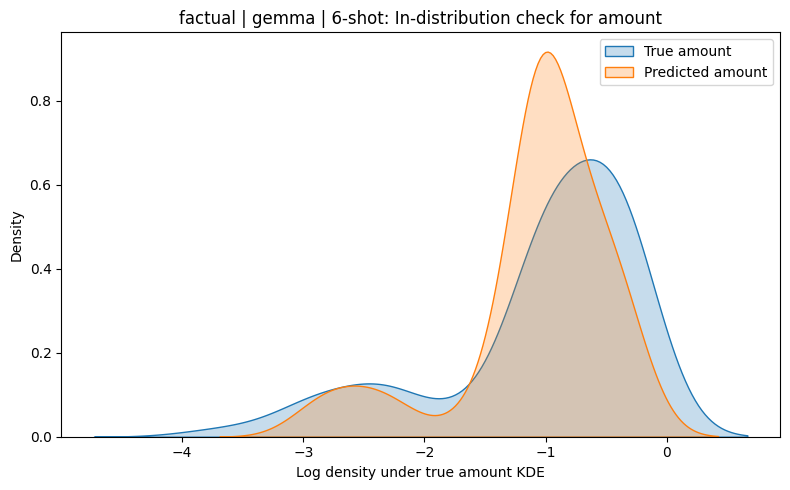

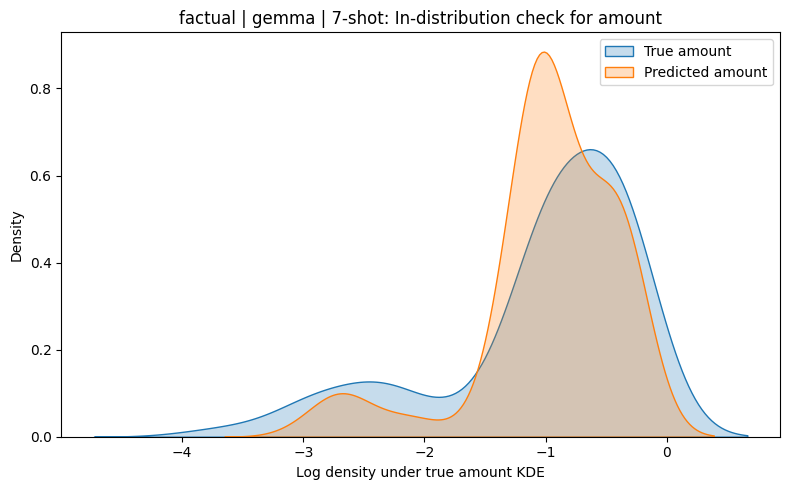

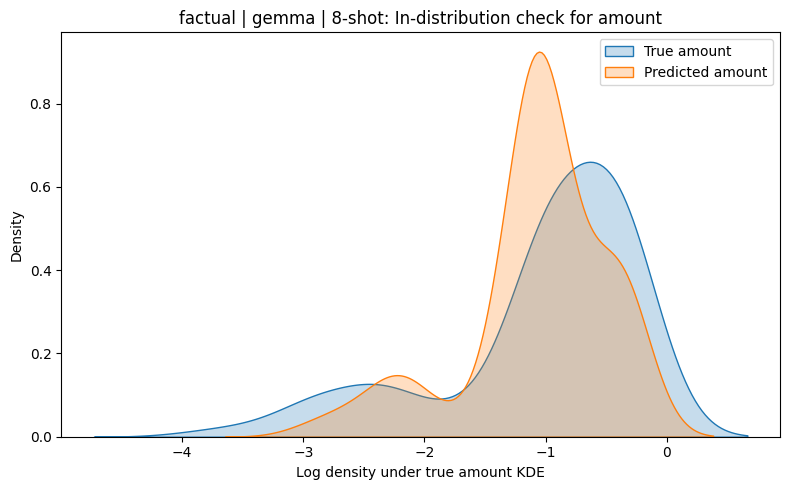

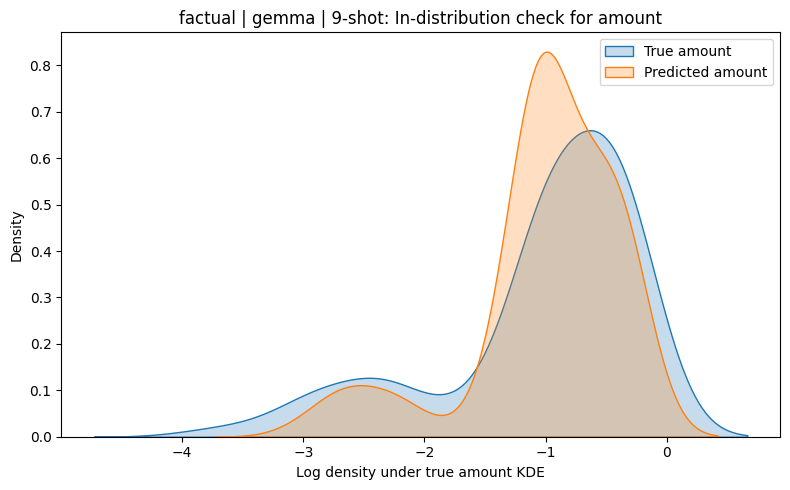

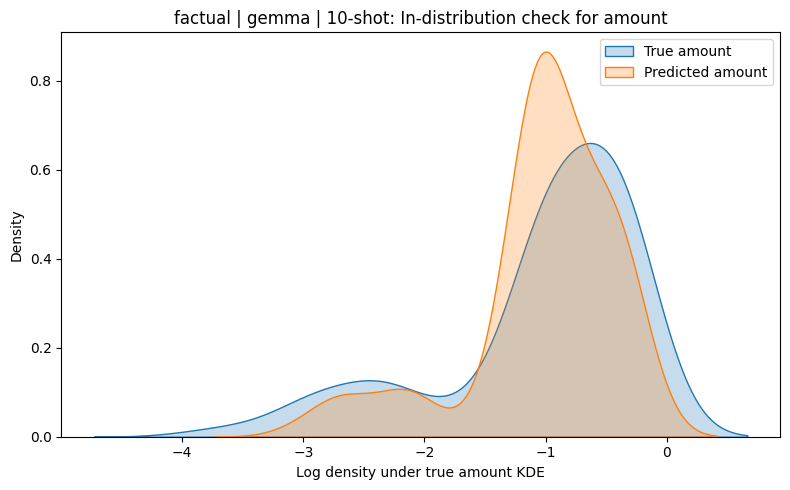

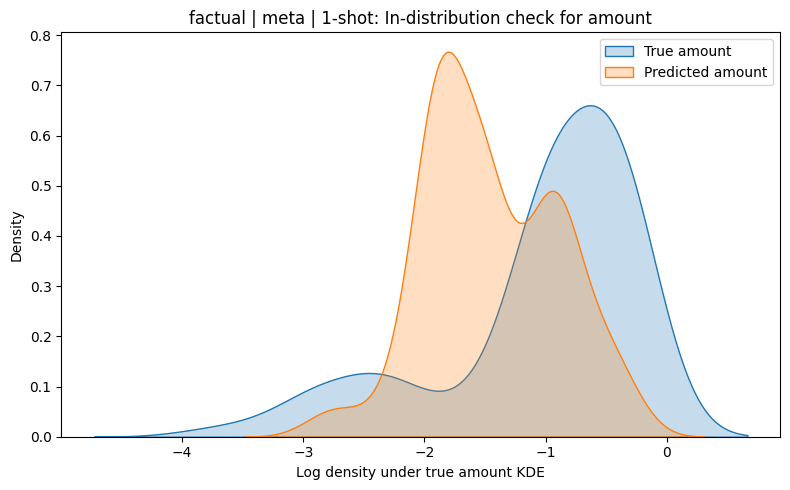

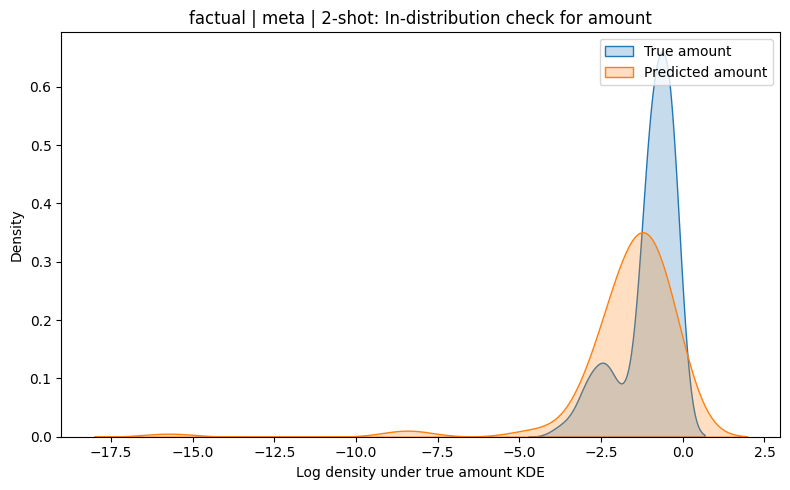

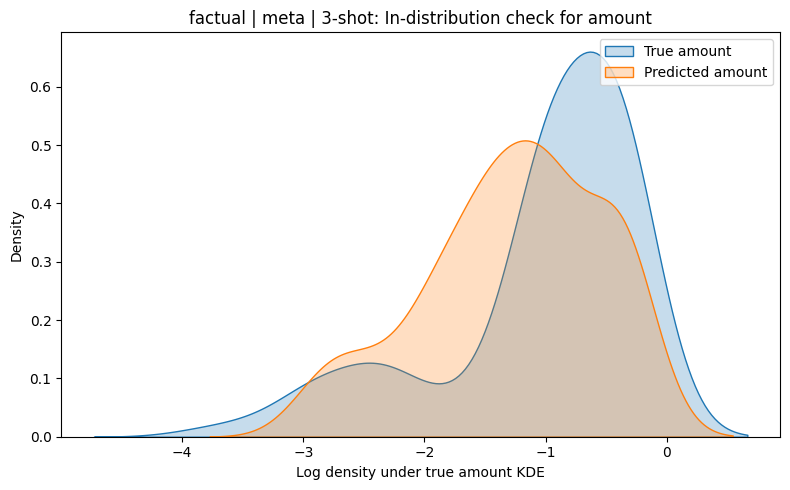

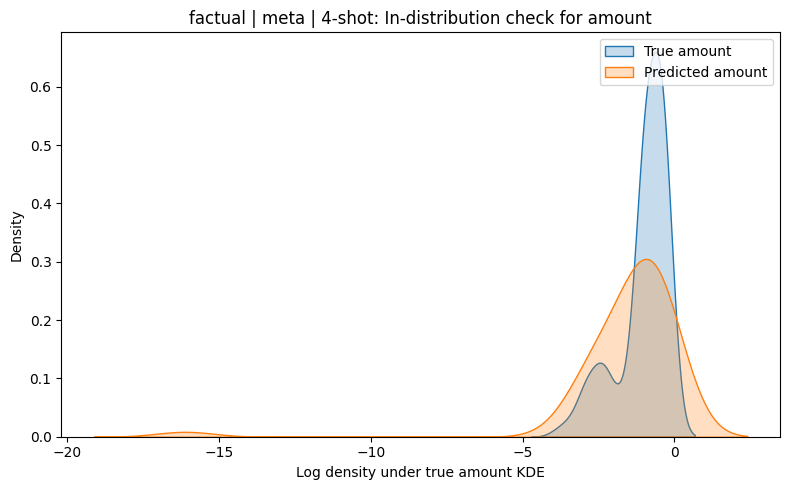

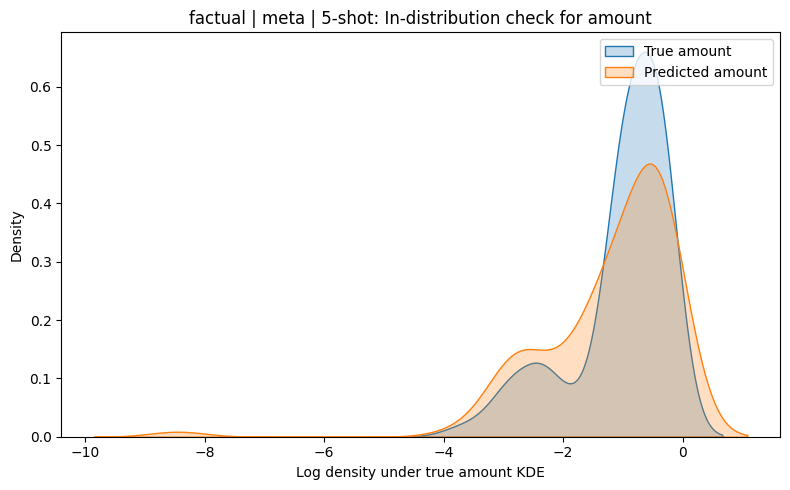

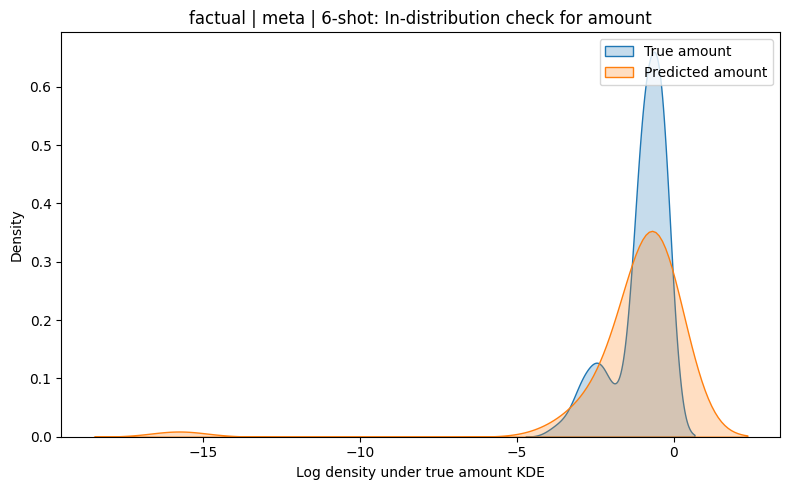

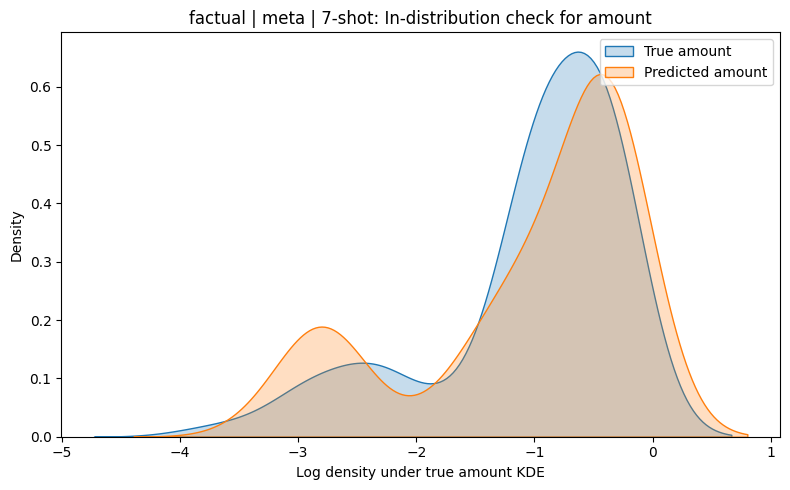

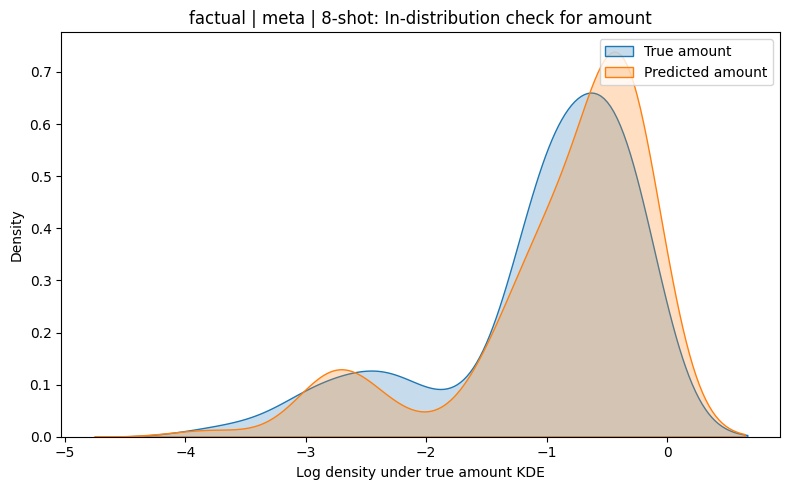

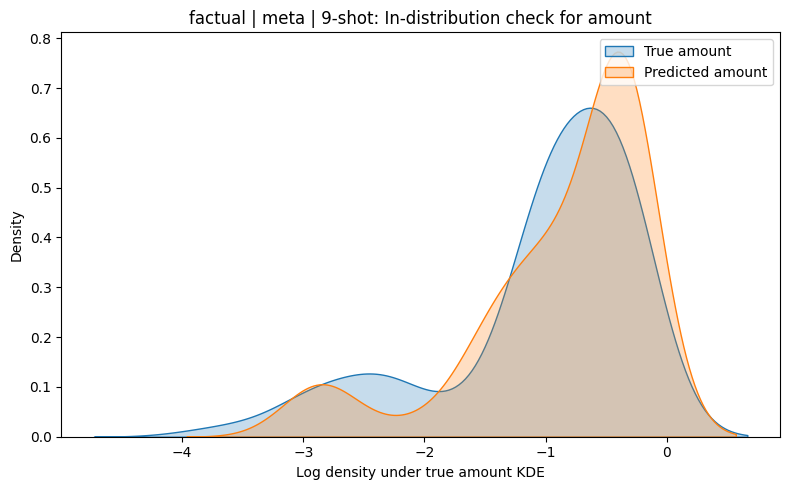

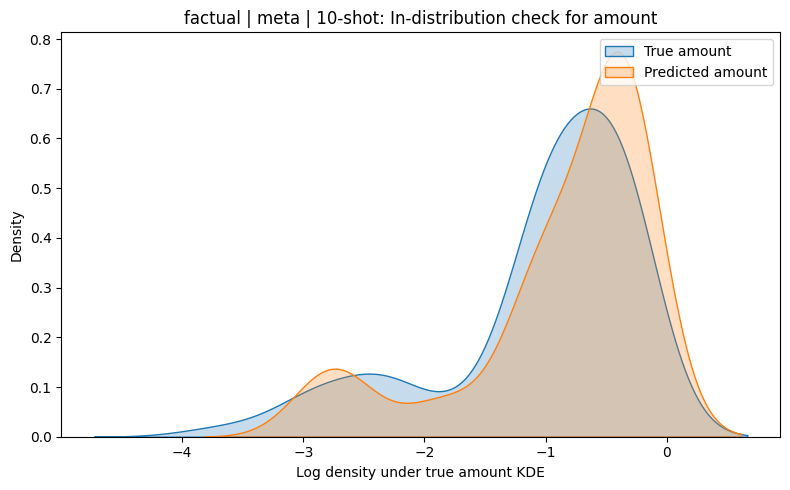

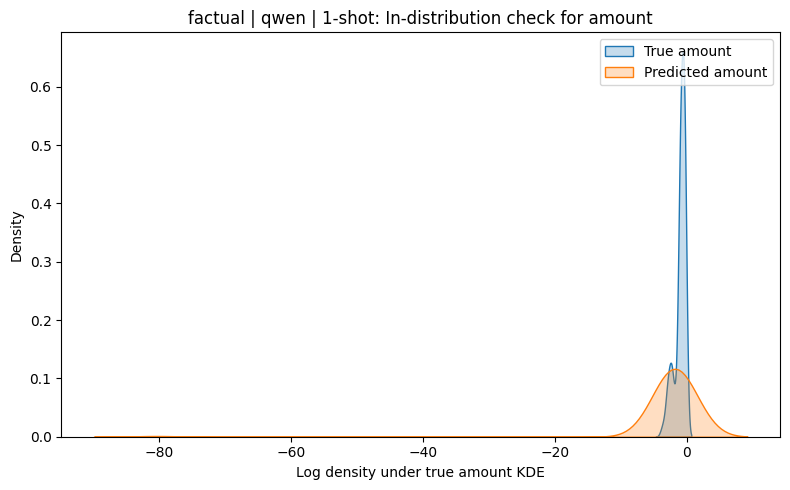

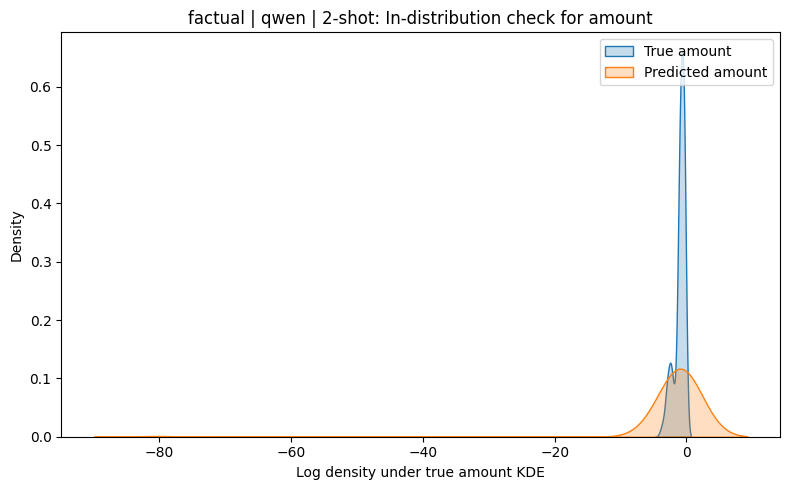

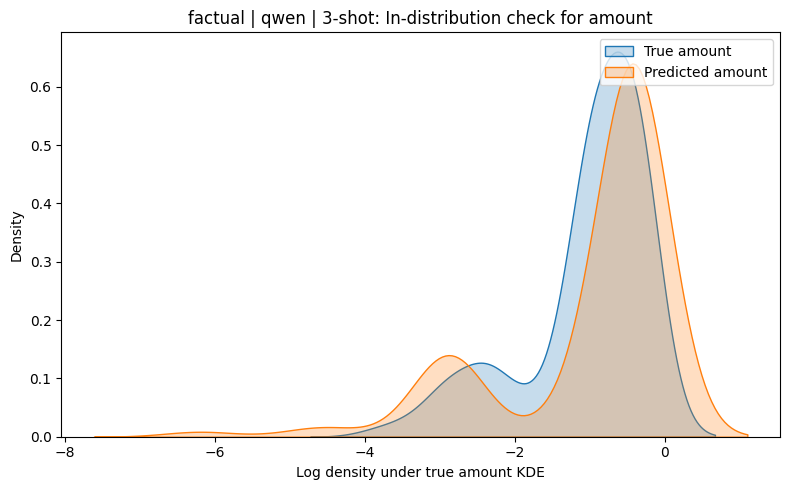

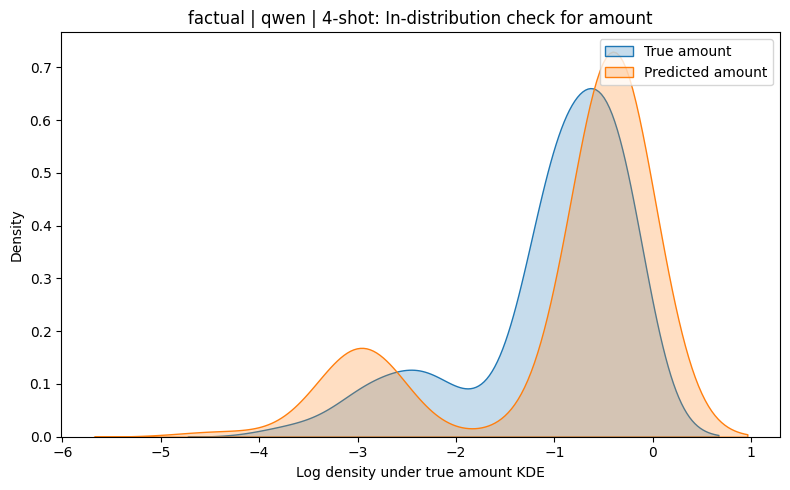

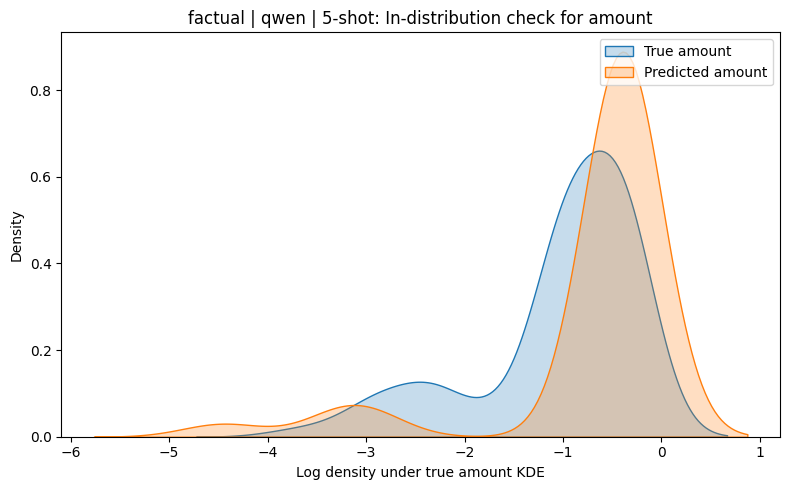

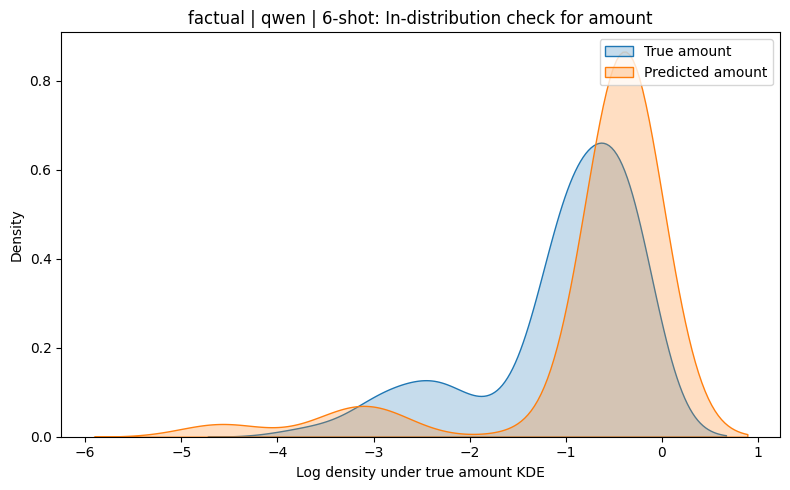

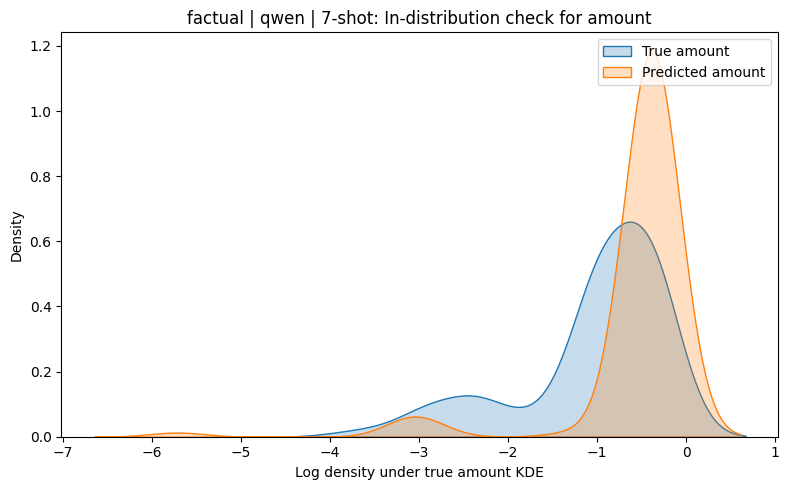

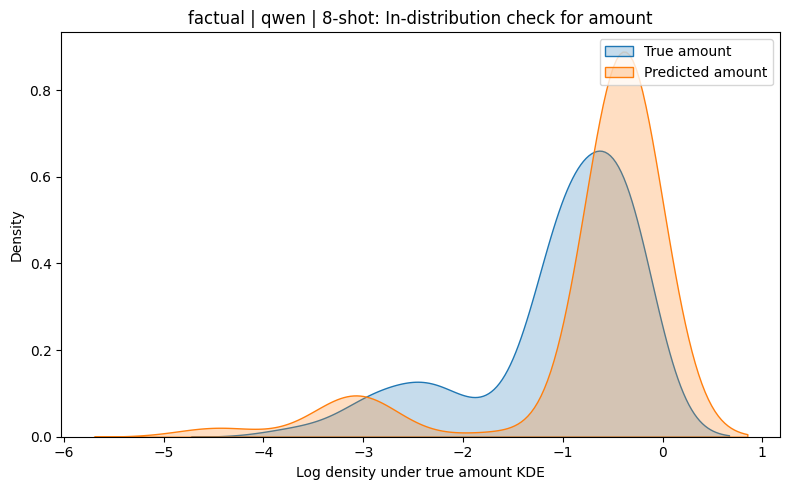

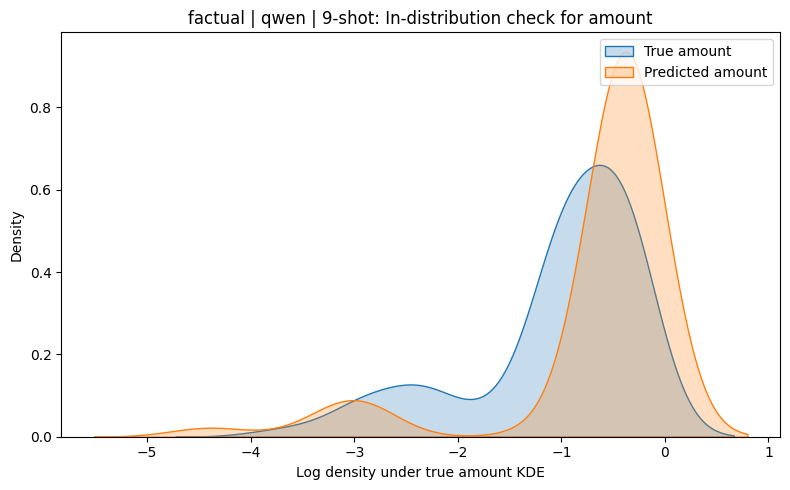

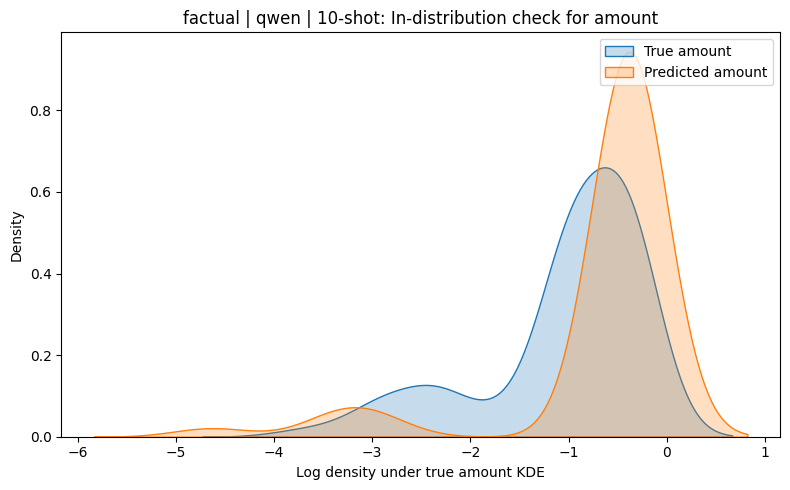

In [5]:
kde_results = []

for model in sorted(all_results["model"].unique()):
    for shot in sorted(all_results["shot"].unique()):
        sub = all_results[
            (all_results["model"] == model) &
            (all_results["shot"] == shot)
        ]

        res = kde_in_distribution_1d(
            sub,
            true_col="true_amount",
            pred_col="pred_amount",
            label="amount",
            setting="factual",
            model=model,
            shot=shot,
        )

        if res is not None:
            kde_results.append(res)

kde_amount_results = pd.concat(kde_results, ignore_index=True)

## Duration Analysis

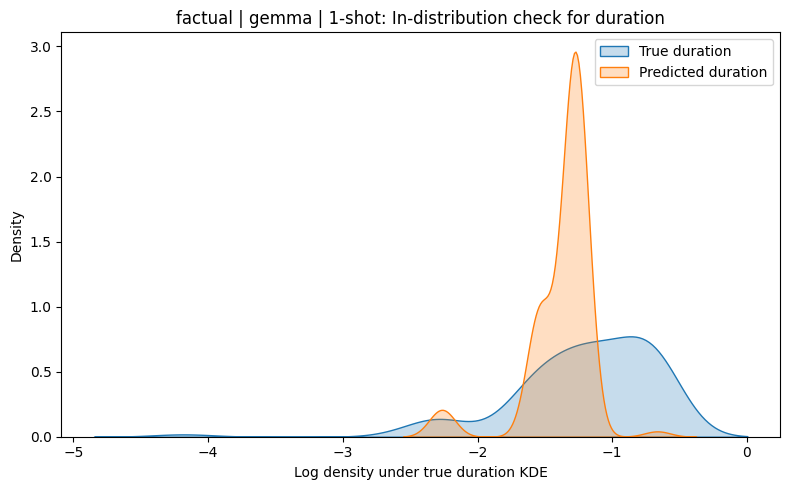

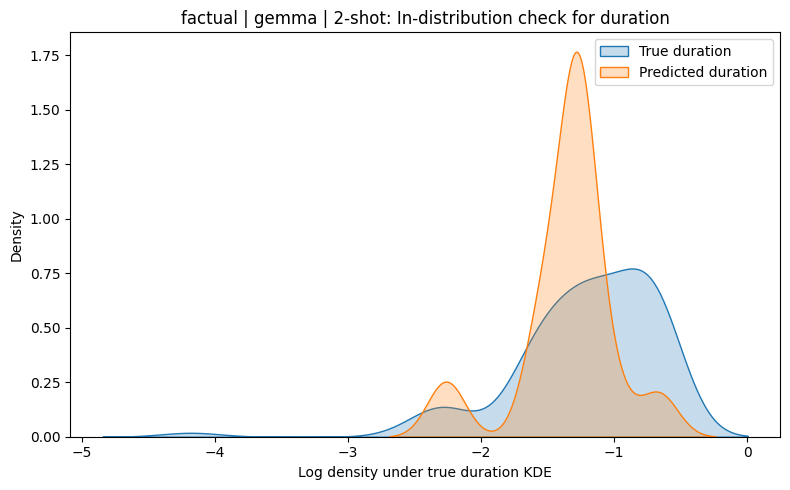

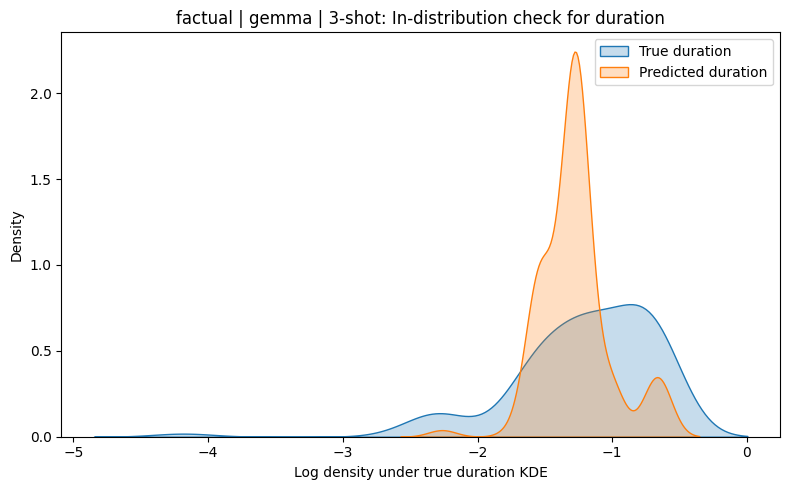

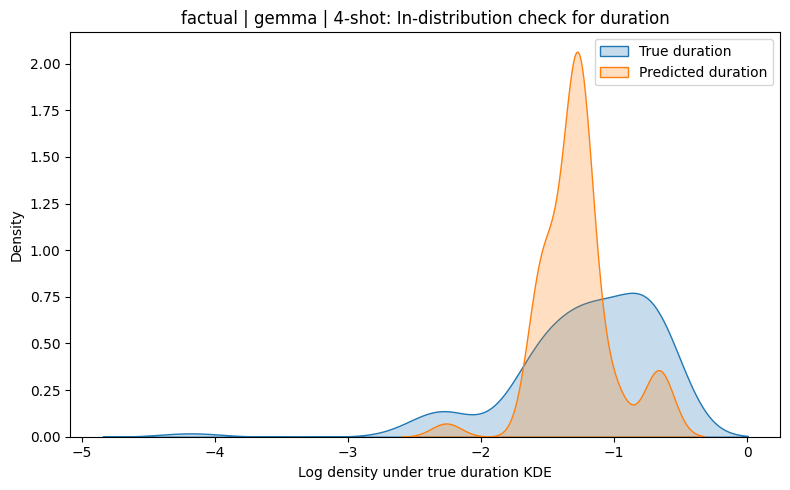

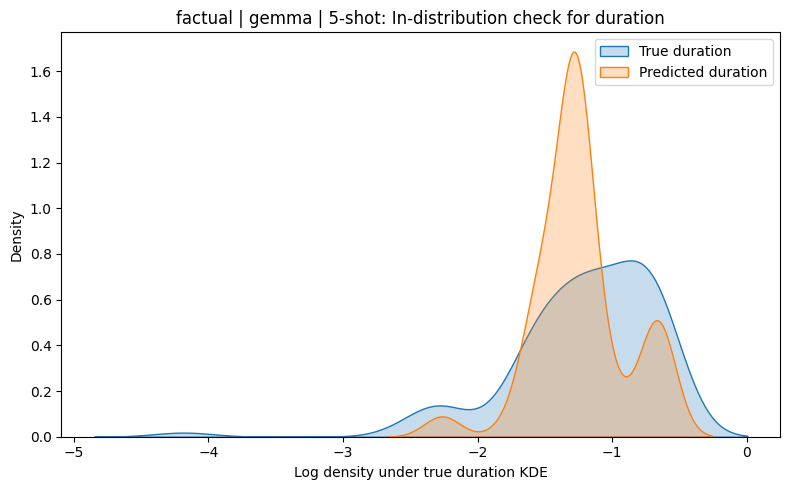

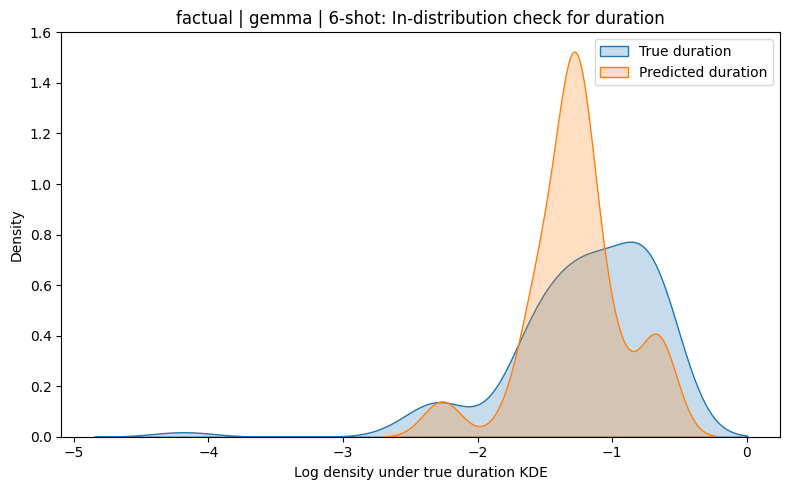

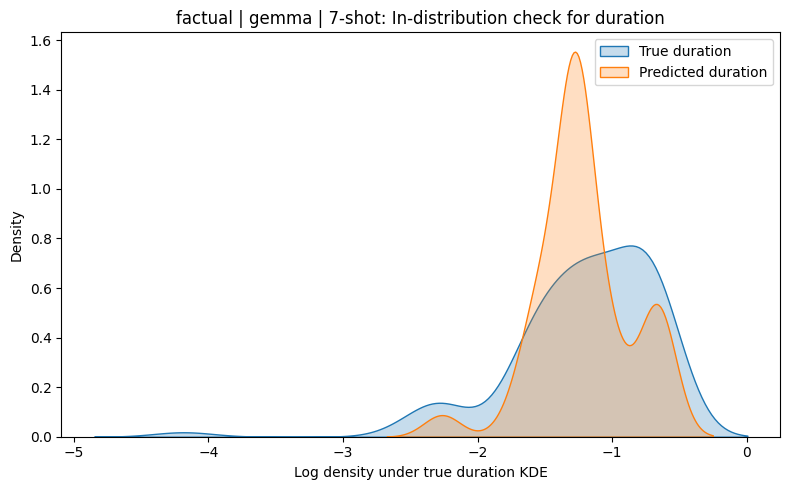

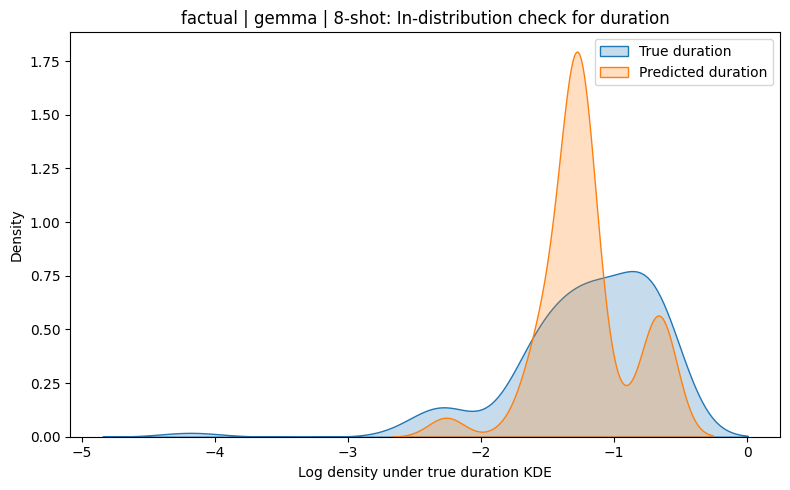

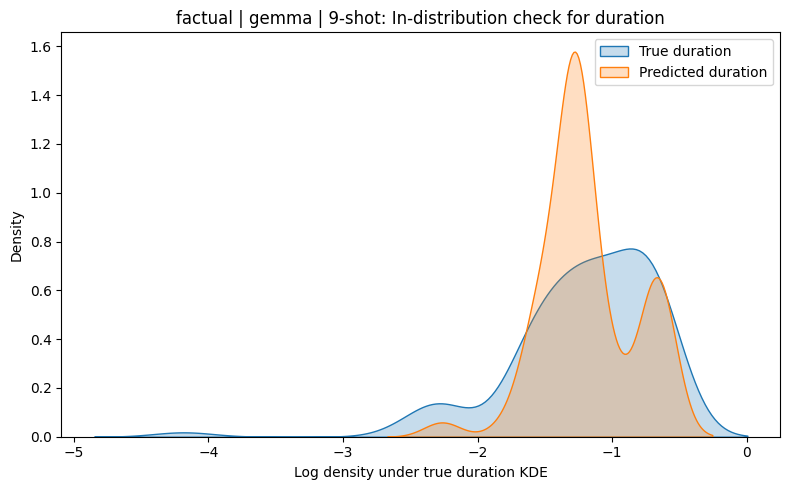

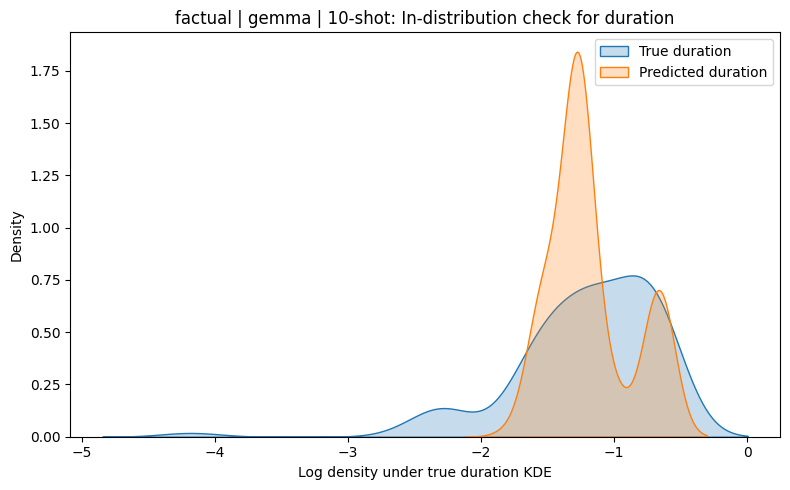

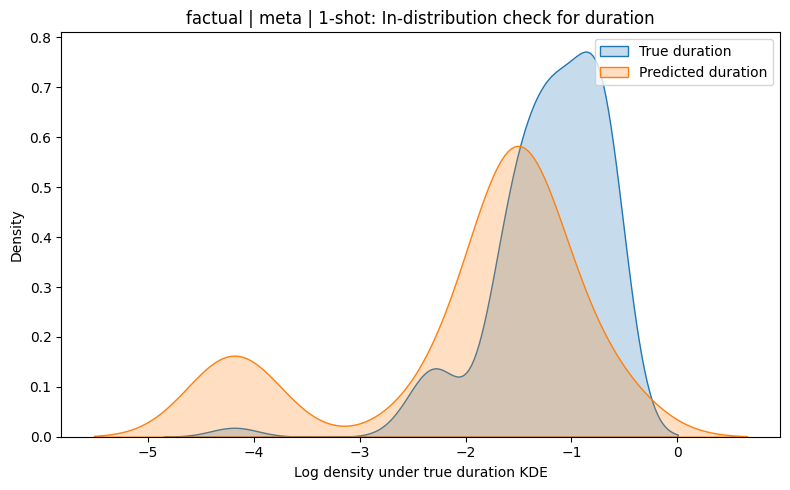

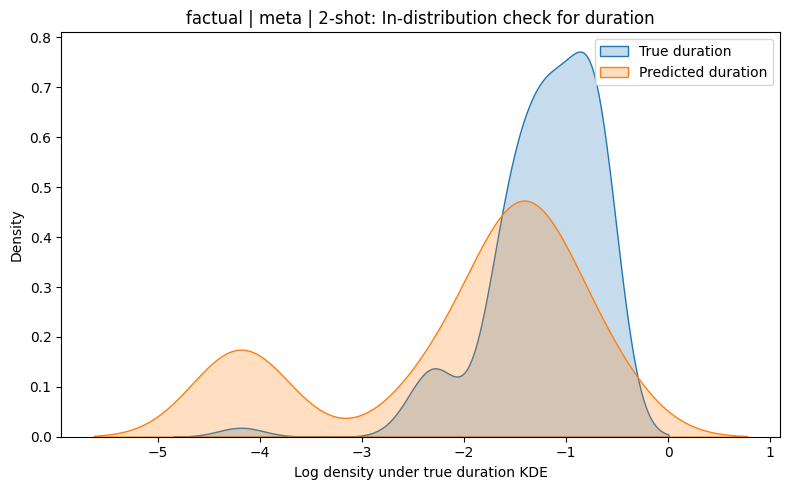

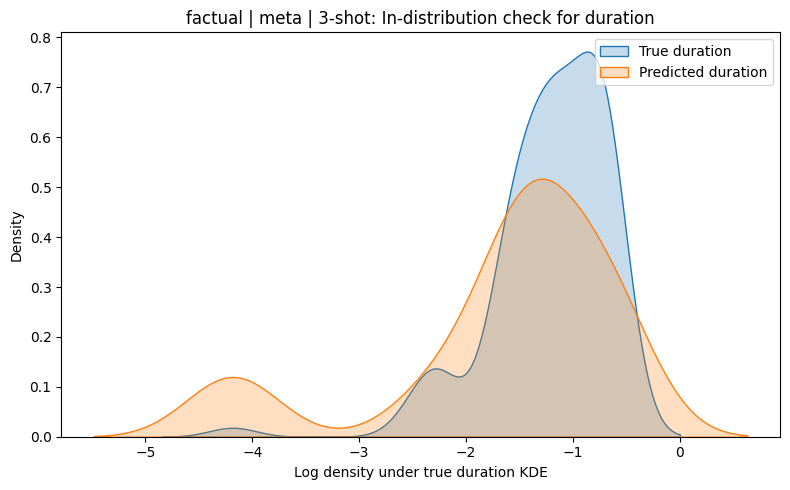

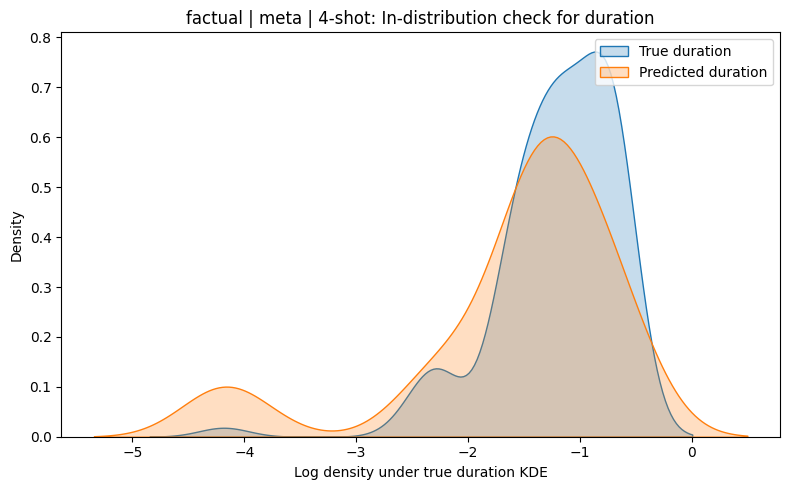

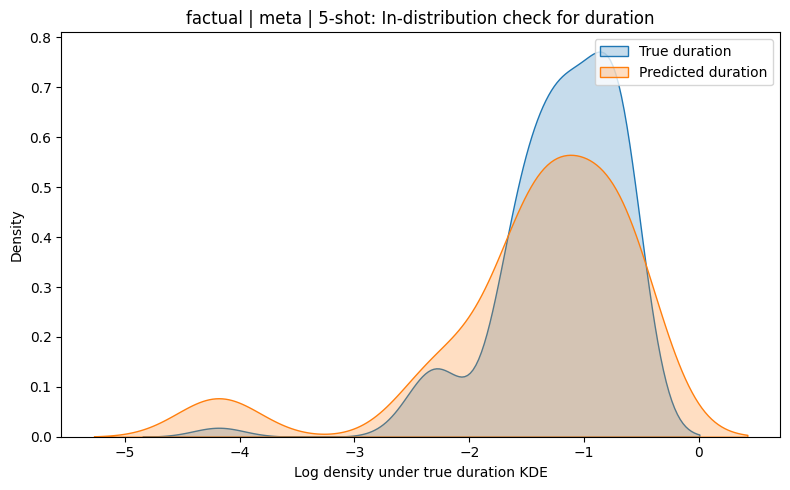

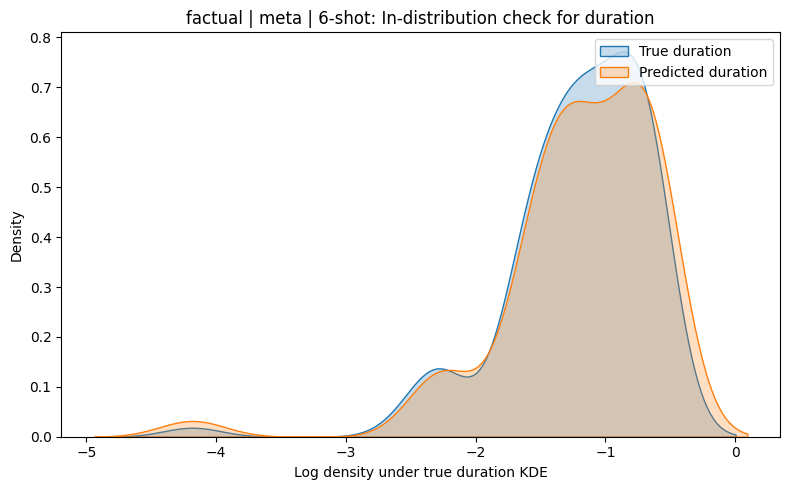

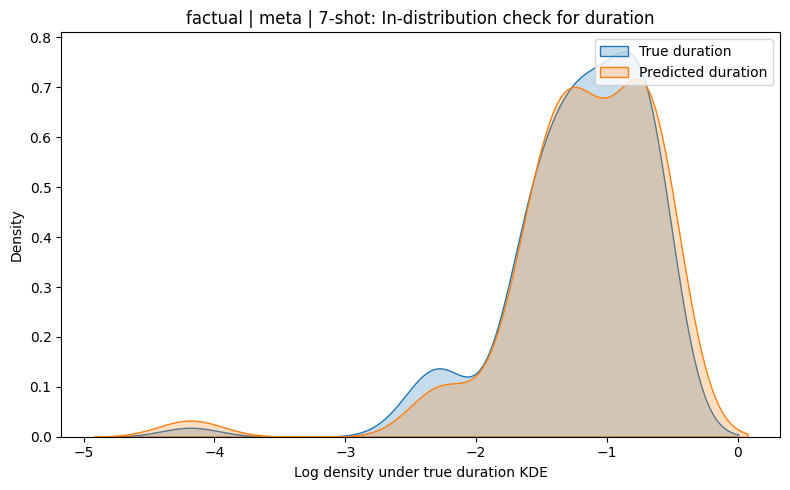

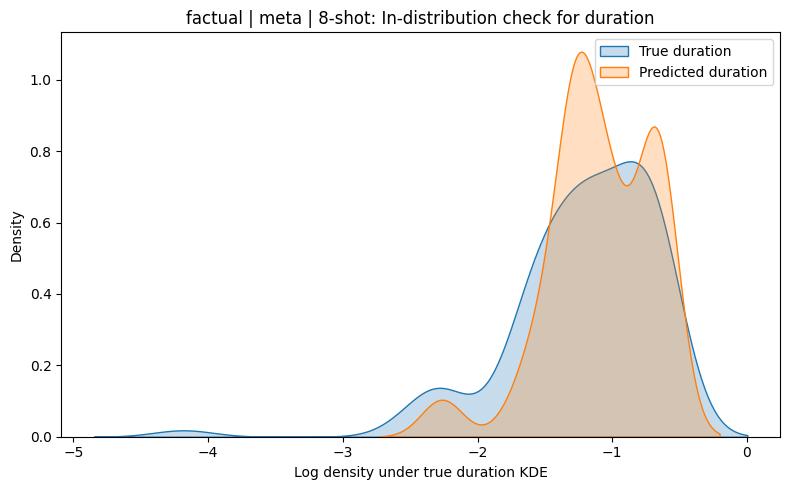

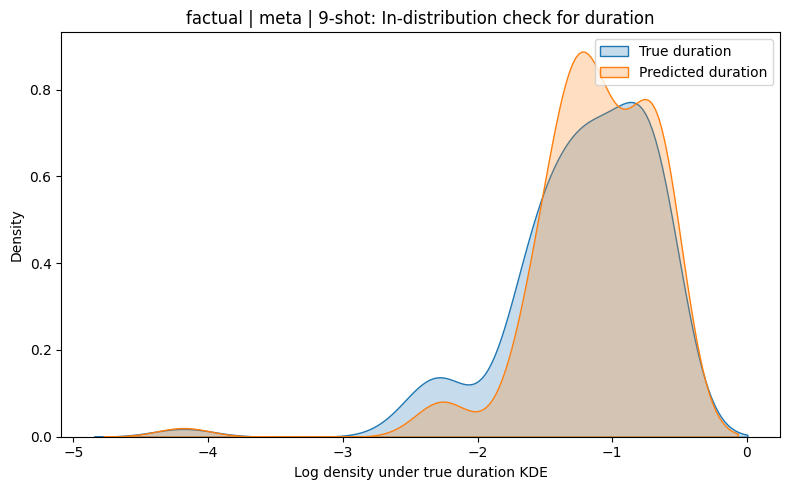

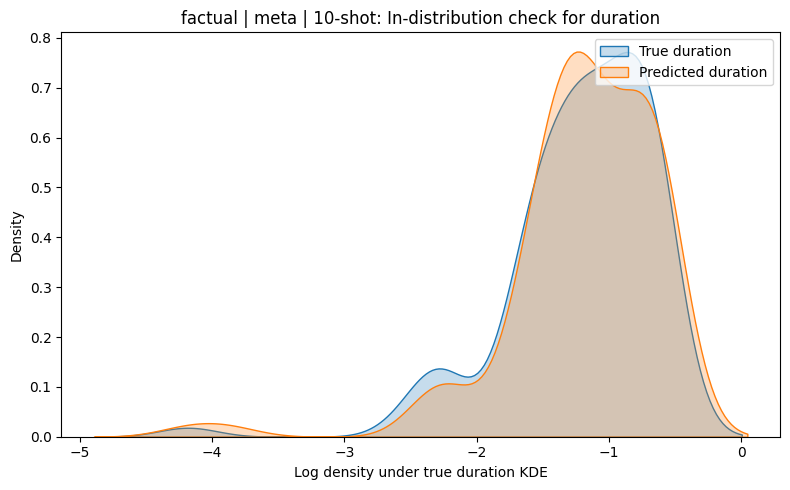

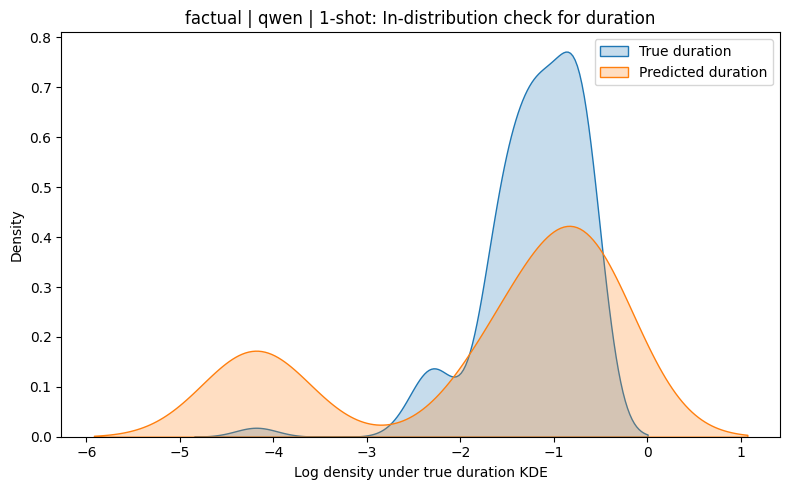

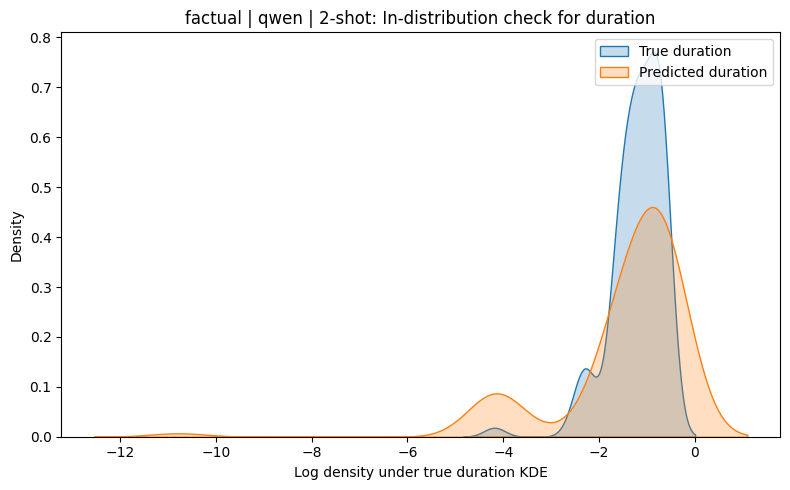

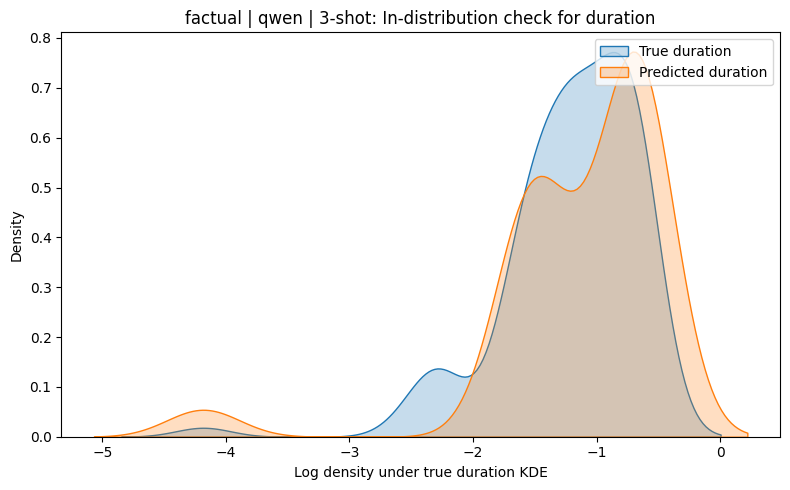

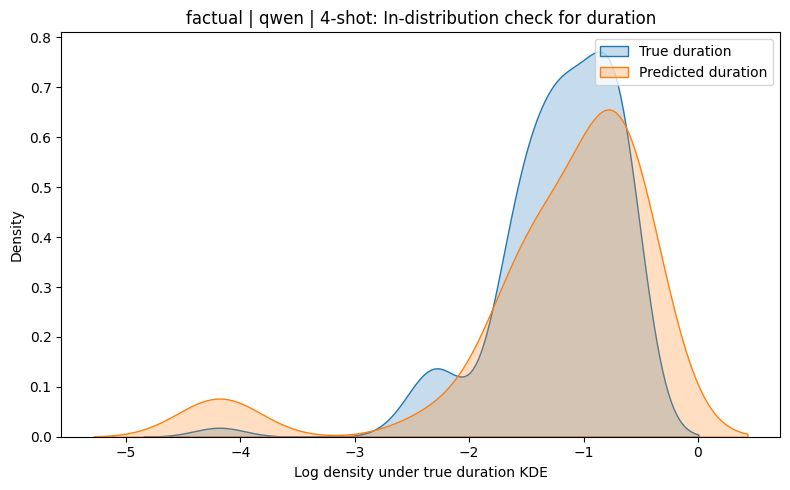

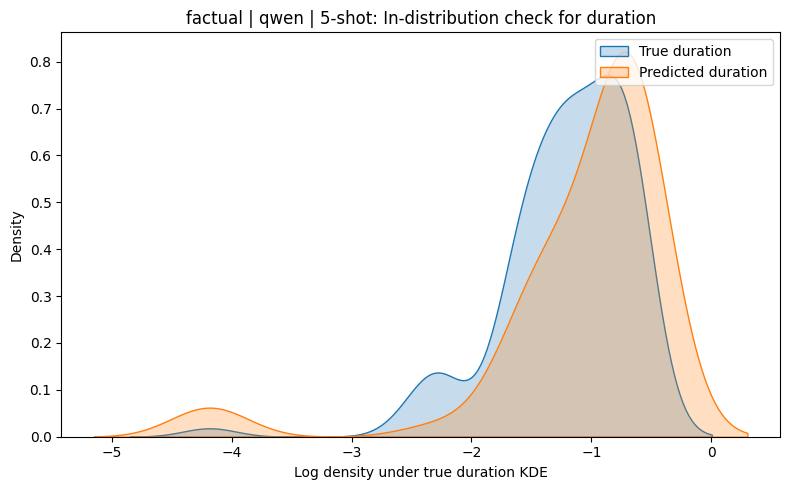

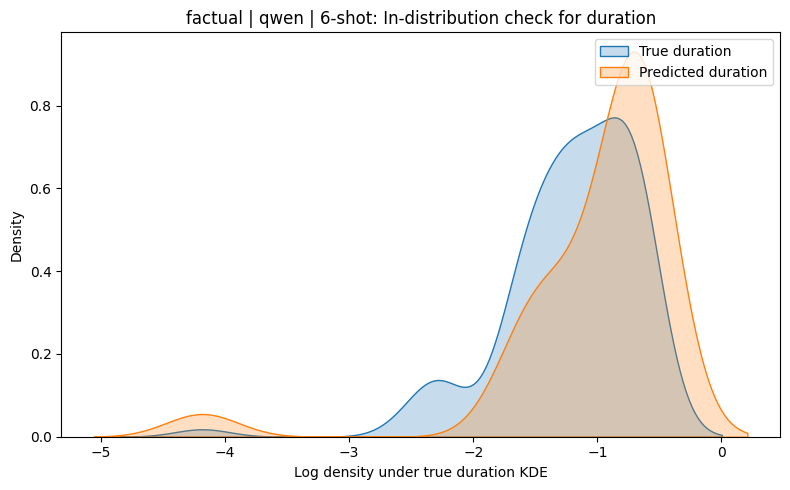

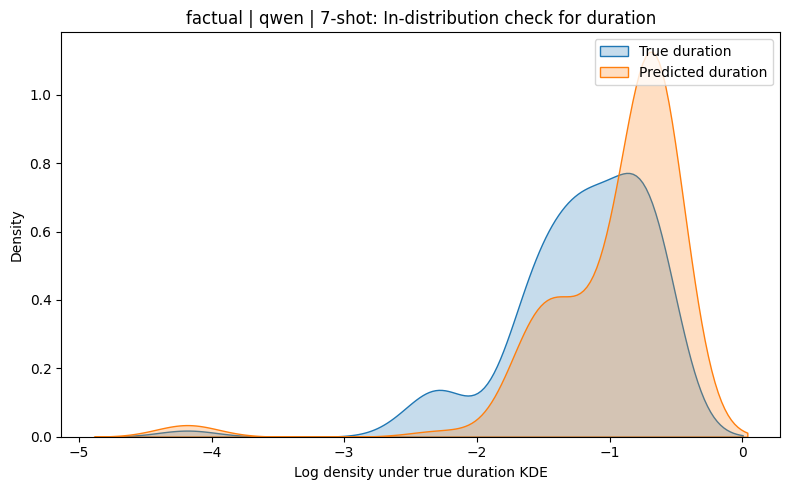

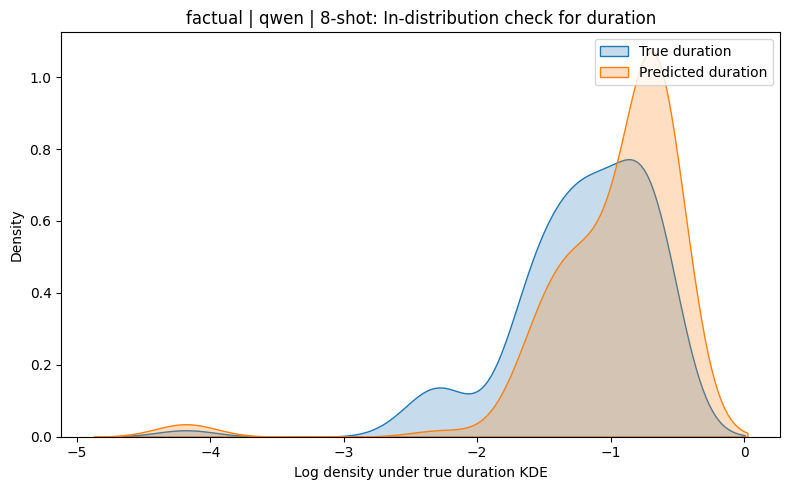

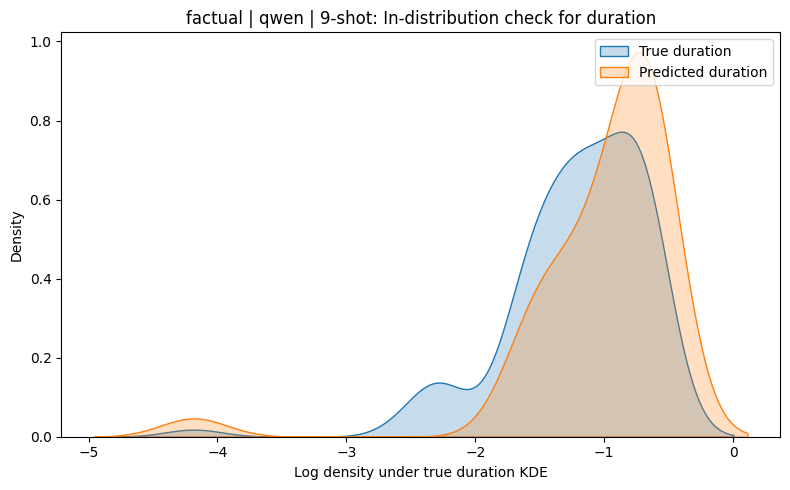

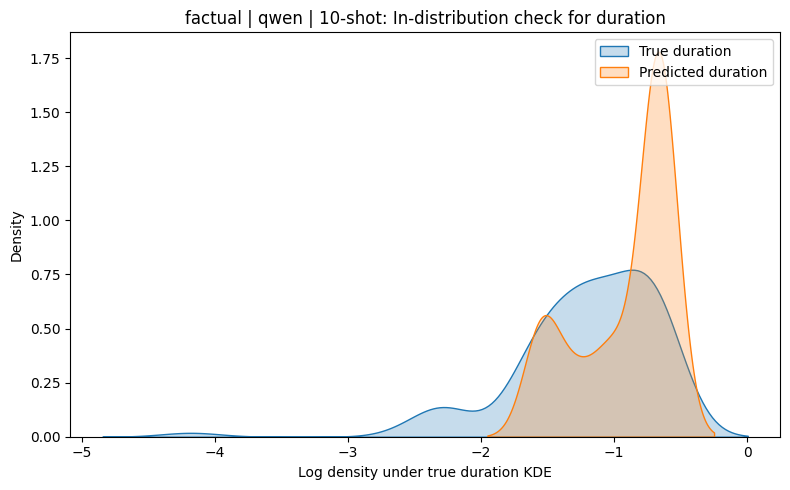

In [6]:
kde_results = []
for model in sorted(all_results["model"].unique()):
    for shot in sorted(all_results["shot"].unique()):
        sub = all_results[
            (all_results["model"] == model) &
            (all_results["shot"] == shot)
        ]

        res = kde_in_distribution_1d(
            sub,
            true_col="true_duration",
            pred_col="pred_duration",
            label="duration",
            setting="factual",
            model=model,
            shot=shot,
        )

        if res is not None:
            kde_results.append(res)

kde_duration_results = pd.concat(kde_results, ignore_index=True)

### Summary stats

In [7]:
def mae_by_shot_model(
    df,
    metric="amount",
    true_amount_col="true_amount",
    pred_amount_col="pred_amount",
    true_duration_col="true_duration",
    pred_duration_col="pred_duration",
    round_digits=3,
):
    """
    Returns a shot x model table of mean absolute error.

    metric:
        "amount"   -> MAE for amount
        "duration" -> MAE for duration
        "both"     -> returns both amount and duration MAE tables
    """

    data = df.copy()

    data["amount_abs_error"] = (data[pred_amount_col] - data[true_amount_col])**2
    # ).square()

    data["duration_abs_error"] = (data[pred_duration_col] - data[true_duration_col])**2
    # ).square()

    if metric == "amount":
        table = data.pivot_table(
            index="shot",
            columns="model",
            values="amount_abs_error",
            aggfunc="mean",
        )

        return table.round(round_digits)

    elif metric == "duration":
        table = data.pivot_table(
            index="shot",
            columns="model",
            values="duration_abs_error",
            aggfunc="mean",
        )

        return table.round(round_digits)

    elif metric == "both":
        amount_table = data.pivot_table(
            index="shot",
            columns="model",
            values="amount_abs_error",
            aggfunc="mean",
        ).round(round_digits)

        duration_table = data.pivot_table(
            index="shot",
            columns="model",
            values="duration_abs_error",
            aggfunc="mean",
        ).round(round_digits)

        return amount_table, duration_table

    else:
        raise ValueError("metric must be one of: 'amount', 'duration', or 'both'")

In [8]:
amount_mae_table = mae_by_shot_model(all_results, metric="amount")
amount_mae_table

model,gemma,meta,qwen
shot,,,
1,7752329.75,14153769.29,26700463.30
2,7756150.39,16232264.99,20657202.54
3,7401759.76,11237291.73,18224631.87
4,7693825.79,15849703.12,17289525.67
5,8790437.29,13122907.19,15953909.76
6,8488697.81,16742514.75,16030938.71
7,7967119.42,13661238.17,15331550.52
8,8544184.11,12649315.32,16038337.33
9,9114026.17,13913445.90,18861086.34


In [9]:
duration_mae_table = mae_by_shot_model(all_results, metric="duration")
duration_mae_table

model,gemma,meta,qwen
shot,,,
1,256.97,585.77,563.97
2,262.73,607.37,473.60
3,218.69,483.41,336.45
4,210.89,426.62,334.03
5,246.69,372.11,362.93
6,240.49,283.83,292.25
7,194.81,304.65,284.90
8,197.97,244.22,240.05
9,203.05,269.57,295.97


In [10]:
def _normalize_probabilities(probs, epsilon=1e-12):
    probs = np.asarray(probs, dtype=float)
    probs = np.maximum(probs, epsilon)
    total = probs.sum()
    if total <= 0:
        return np.ones_like(probs, dtype=float) / len(probs)
    return probs / total


def _probability_mass_from_samples(x, y=None, bins=50, categorical=None):
    x = np.asarray(x).ravel()
    if y is not None:
        y = np.asarray(y).ravel()

    if categorical is None:
        if x.dtype.kind in ("O", "U", "S") or (y is not None and y.dtype.kind in ("O", "U", "S")):
            categorical = True
        else:
            categorical = (
                x.dtype.kind in ("i", "u", "b") and len(np.unique(x)) <= min(50, len(x))
            )
            if y is not None:
                categorical = categorical or (
                    y.dtype.kind in ("i", "u", "b") and len(np.unique(y)) <= min(50, len(y))
                )

    if categorical:
        values = np.union1d(np.unique(x), np.unique(y)) if y is not None else np.unique(x)
        p = np.array([(x == value).sum() for value in values], dtype=float)
        q = None
        if y is not None:
            q = np.array([(y == value).sum() for value in values], dtype=float)
        return p, q

    if y is None:
        counts, _ = np.histogram(x[~np.isnan(x)], bins=bins, density=False)
        return counts

    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    if x.size == 0 or y.size == 0:
        return np.zeros(bins, dtype=float), np.zeros(bins, dtype=float)

    low = min(x.min(), y.min())
    high = max(x.max(), y.max())
    if low == high:
        low -= 0.5
        high += 0.5

    p, _ = np.histogram(x, bins=bins, range=(low, high), density=False)
    q, _ = np.histogram(y, bins=bins, range=(low, high), density=False)
    return p, q


def kl_divergence(p, q, base=2, epsilon=1e-12):
    p = _normalize_probabilities(p, epsilon=epsilon)
    q = _normalize_probabilities(q, epsilon=epsilon)
    mask = p > 0
    return np.sum(p[mask] * np.log(p[mask] / q[mask])) / np.log(base)


def jensen_shannon_divergence(samples_a, samples_b, bins=50, categorical=None, epsilon=1e-12, base=2):
    p, q = _probability_mass_from_samples(samples_a, samples_b, bins=bins, categorical=categorical)
    p = _normalize_probabilities(p, epsilon=epsilon)
    q = _normalize_probabilities(q, epsilon=epsilon)
    m = 0.5 * (p + q)
    return 0.5 * kl_divergence(p, m, base=base, epsilon=epsilon) + 0.5 * kl_divergence(q, m, base=base, epsilon=epsilon)


def jensen_shannon_distance(samples_a, samples_b, **kwargs):
    return np.sqrt(jensen_shannon_divergence(samples_a, samples_b, **kwargs))


def total_variation_distance(samples_a, samples_b, bins=50, categorical=None):
    p, q = _probability_mass_from_samples(samples_a, samples_b, bins=bins, categorical=categorical)
    p = _normalize_probabilities(p)
    q = _normalize_probabilities(q)
    return 0.5 * np.sum(np.abs(p - q))


def wasserstein_distance(samples_a, samples_b, bins=50):
    x = np.asarray(samples_a, dtype=float).ravel()
    y = np.asarray(samples_b, dtype=float).ravel()
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    if x.size == 0 or y.size == 0:
        return np.nan

    low = min(x.min(), y.min())
    high = max(x.max(), y.max())
    if low == high:
        low -= 0.5
        high += 0.5

    bins = min(max(int(bins), 10), 1000)
    p_hist, _ = np.histogram(x, bins=bins, range=(low, high), density=False)
    q_hist, _ = np.histogram(y, bins=bins, range=(low, high), density=False)

    p_hist = p_hist.astype(float) / p_hist.sum()
    q_hist = q_hist.astype(float) / q_hist.sum()

    edges = np.linspace(low, high, bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    cdf_p = np.cumsum(p_hist)
    cdf_q = np.cumsum(q_hist)
    return np.sum(np.abs(cdf_p - cdf_q) * np.diff(edges))


def _rbf_kernel(X, Y, gamma=None):
    X = np.asarray(X, dtype=float).reshape(-1, 1)
    Y = np.asarray(Y, dtype=float).reshape(-1, 1)
    sq_dists = np.sum((X[:, None, :] - Y[None, :, :]) ** 2, axis=-1)
    return np.exp(-gamma * sq_dists)


def maximum_mean_discrepancy(samples_a, samples_b, gamma=None, biased=True):
    x = np.asarray(samples_a, dtype=float).reshape(-1, 1)
    y = np.asarray(samples_b, dtype=float).reshape(-1, 1)
    if x.size == 0 or y.size == 0:
        raise ValueError("Both sample sets must contain at least one value.")
    if gamma is None:
        var = np.var(np.vstack([x, y]))
        gamma = 1.0 / (2 * var) if var > 0 else 1.0
    Kxx = _rbf_kernel(x, x, gamma=gamma)
    Kyy = _rbf_kernel(y, y, gamma=gamma)
    Kxy = _rbf_kernel(x, y, gamma=gamma)
    if biased or len(x) < 2 or len(y) < 2:
        return Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()
    m = len(x)
    n = len(y)
    return ((Kxx.sum() - np.trace(Kxx)) / (m * (m - 1)) + (Kyy.sum() - np.trace(Kyy)) / (n * (n - 1)) - 2 * Kxy.mean())


def compare_distribution_distances(samples_a, samples_b, bins=50, categorical=None, gamma=None, epsilon=1e-12):
    jsd = jensen_shannon_divergence(samples_a, samples_b, bins=bins, categorical=categorical, epsilon=epsilon)
    return {
        "jsd": jsd,
        "js_distance": np.sqrt(jsd),
        "total_variation": total_variation_distance(samples_a, samples_b, bins=bins, categorical=categorical),
        "wasserstein": wasserstein_distance(samples_a, samples_b, bins=bins),
        "mmd_rbf": maximum_mean_discrepancy(samples_a, samples_b, gamma=gamma),
    }




In [11]:
def distribution_distances_by_group(
    df,
    group_cols,
    true_col,
    pred_col,
    bins=50,
    gamma=None,
    mae_col_name=None,
):
    rows = []
    grouped = df.groupby(group_cols)
    for group_values, sub in grouped:
        paired = sub[[true_col, pred_col]].dropna()
        if len(paired) == 0:
            continue

        truth = paired[true_col].to_numpy(dtype=float)
        pred = paired[pred_col].to_numpy(dtype=float)

        dists = compare_distribution_distances(
            truth,
            pred,
            bins=bins,
            gamma=gamma,
        )

        if isinstance(group_values, tuple):
            row = dict(zip(group_cols, group_values))
        else:
            row = {group_cols[0]: group_values}

        row.update(dists)
        if mae_col_name is None:
            mae_col_name = "mae"
        row[mae_col_name] = np.mean(np.abs(pred - truth))
        row["n"] = len(sub)
        rows.append(row)

    return pd.DataFrame(rows)

amount_distance_by_model_shot = distribution_distances_by_group(
    all_results,
    ["model", "shot"],
    "true_amount",
    "pred_amount",
    bins=50,
    mae_col_name="amount_mae",
)

duration_distance_by_model_shot = distribution_distances_by_group(
    all_results,
    ["model", "shot"],
    "true_duration",
    "pred_duration",
    bins=50,
    mae_col_name="duration_mae",
)

display(amount_distance_by_model_shot)
duration_distance_by_model_shot

,model,shot,jsd,js_distance,total_variation,wasserstein,mmd_rbf,amount_mae,n
0,gemma,1,0.516339,0.718568,0.67,1384.2468,0.196094,2220.25,100
1,gemma,2,0.407035,0.637993,0.59,1177.6428,0.121045,2124.01,100
2,gemma,3,0.305301,0.552540,0.53,1059.4456,0.094927,2027.38,100
3,gemma,4,0.349639,0.591303,0.53,968.7432,0.079148,2094.89,100
4,gemma,5,0.271576,0.521130,0.47,897.5216,0.062506,2270.53,100
5,gemma,6,0.303293,0.550721,0.54,992.3628,0.076311,2199.87,100
6,gemma,7,0.320732,0.566332,0.52,899.8348,0.058151,2134.14,100
7,gemma,8,0.359601,0.599668,0.55,976.1704,0.076187,2260.57,100
8,gemma,9,0.329889,0.574360,0.52,839.6916,0.047136,2241.33,100
9,gemma,10,0.358442,0.598701,0.55,879.0160,0.055239,2240.23,100


,model,shot,jsd,js_distance,total_variation,wasserstein,mmd_rbf,duration_mae,n
0,gemma,1,0.513673,0.716710,0.70,7.4196,0.248949,13.35,100
1,gemma,2,0.350249,0.591819,0.56,6.0048,0.144116,13.45,100
2,gemma,3,0.343629,0.586199,0.57,6.3936,0.166529,12.53,100
3,gemma,4,0.347477,0.589472,0.57,6.2964,0.154140,12.23,100
4,gemma,5,0.307803,0.554800,0.49,5.1520,0.099109,13.17,100
5,gemma,6,0.277851,0.527116,0.44,4.8832,0.095110,12.57,100
6,gemma,7,0.269820,0.519442,0.41,5.1840,0.092842,11.39,100
7,gemma,8,0.330499,0.574890,0.49,5.6560,0.100184,11.35,100
8,gemma,9,0.311156,0.557813,0.47,4.9952,0.068924,11.57,100
9,gemma,10,0.347135,0.589181,0.51,5.5104,0.092420,11.43,100


In [12]:
def rank_best_shots(distance_df, group_col='model', metric_cols=None):
    if metric_cols is None:
        metric_cols = ['jsd', 'total_variation', 'wasserstein', 'mmd_rbf', 'amount_mae']

    ranked = distance_df.copy()
    for col in metric_cols:
        ranked[f'{col}_rank'] = ranked.groupby(group_col)[col].rank(method='dense', ascending=True)

    ranked['avg_rank'] = ranked[[f'{col}_rank' for col in metric_cols]].mean(axis=1)
    ranked = ranked.sort_values([group_col, 'avg_rank'] + metric_cols, ascending=[True, True] + [True] * len(metric_cols))
    best = ranked.groupby(group_col, as_index=False).first()
    return best.sort_values([group_col])

best_amount_shots = rank_best_shots(
    amount_distance_by_model_shot,
    group_col='model',
    metric_cols=['jsd', 'total_variation', 'wasserstein', 'mmd_rbf', 'amount_mae'],
)

best_duration_shots = rank_best_shots(
    duration_distance_by_model_shot,
    group_col='model',
    metric_cols=['jsd', 'total_variation', 'wasserstein', 'mmd_rbf', 'duration_mae'],
)

print('Best shot per model for amount distance metrics + MAE:')
display(best_amount_shots)

print('Best shot per model for duration distance metrics + MAE:')
display(best_duration_shots)


Best shot per model for amount distance metrics + MAE:


,model,shot,jsd,js_distance,total_variation,wasserstein,mmd_rbf,amount_mae,n,jsd_rank,total_variation_rank,wasserstein_rank,mmd_rbf_rank,amount_mae_rank,avg_rank
0,gemma,9,0.329889,0.574360,0.52,839.6916,0.047136,2241.33,100,5.0,2.0,1.0,1.0,8.0,3.4
1,meta,8,0.281904,0.530947,0.45,474.9936,0.006466,2588.58,100,1.0,1.0,2.0,1.0,2.0,1.4
2,qwen,2,0.463297,0.680659,0.64,1406.4224,0.071357,3202.00,100,1.0,1.0,4.0,1.0,9.0,3.2


Best shot per model for duration distance metrics + MAE:


,model,shot,jsd,js_distance,total_variation,wasserstein,mmd_rbf,duration_mae,n,jsd_rank,total_variation_rank,wasserstein_rank,mmd_rbf_rank,duration_mae_rank,avg_rank
0,gemma,7,0.269820,0.519442,0.41,5.1840,0.092842,11.39,100,1.0,1.0,4.0,3.0,2.0,2.2
1,meta,9,0.118372,0.344052,0.28,1.8684,0.008870,12.57,100,1.0,1.0,3.0,4.0,2.0,2.2
2,qwen,4,0.282028,0.531063,0.47,3.2832,0.004671,13.17,100,3.0,4.0,1.0,1.0,5.0,2.8
